# HJB equation - Deep BSDE vs Monte Carlo

This notebook compares the Deep BSDE solver with a plain Monte Carlo (MC) solver on the Hamilton–Jacobi–Bellman (HJB) equation. The HJB equation is nonlinear, but the Cole–Hopf transformation turns it into a linear heat equation, so MC through the Feynman–Kac formula applies and gives an accurate reference value.

In [1]:
import time
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt

np.random.seed(0)
torch.manual_seed(0)

Consider the HJB equation
\begin{equation}
    \partial_t u + \Delta u - \lambda |\nabla u|^2 = 0, \qquad u(T, x) = g(x) = \ln\Big(\tfrac{1}{2}\big(1 + |x|^2\big)\Big), \qquad x \in \mathbb{R}^d
\end{equation}
It arises from a stochastic control problem where $\lambda > 0$ weights the control cost. We consider $d = 100$, $\xi = 0$, $T = 1$, $t = 0$, $N = 20$, $\Delta t = T/N$ and $\lambda = 1$.

## Monte Carlo via the Cole–Hopf transformation

Let $w = e^{-\lambda u}$. Then $\partial_t w = -\lambda w\,\partial_t u$, $\nabla w = -\lambda w \nabla u$ and $\Delta w = -\lambda w \Delta u + \lambda^2 w |\nabla u|^2$, so
\begin{equation}
    \partial_t w + \Delta w = -\lambda w\big(\partial_t u + \Delta u - \lambda|\nabla u|^2\big) = 0, \qquad w(T, x) = e^{-\lambda g(x)}
\end{equation}
This is a backward heat equation with diffusion $\sigma = \sqrt{2}$, i.e. $dX_s = \sqrt{2}\,dW_s$. By Feynman–Kac (as for the BHE notebook)
\begin{equation}
    w(t, x) = \mathbb{E}\big[e^{-\lambda g(x + \sqrt{2} W_{T-t})}\big] \quad \Rightarrow \quad u(t, x) = -\frac{1}{\lambda}\ln \mathbb{E}\big[e^{-\lambda g(x + \sqrt{2} W_{T-t})}\big]
\end{equation}
Since $X_T$ can be sampled directly there is no time discretization error, so a single step is used. The expectation is approximated with $M$ samples
\begin{equation}
    u(t, x) \approx -\frac{1}{\lambda}\ln\Big(\frac{1}{M}\sum_{i=1}^M e^{-\lambda g(x + \sqrt{2(T-t)}Z^{(i)})}\Big), \qquad Z^{(i)} \sim N(0, I_d)
\end{equation}

Two practical points:
- For large $\lambda$ the weights $e^{-\lambda g}$ under- or overflow, so the log of the mean is computed with the log-sum-exp trick (shift by the maximum exponent).
- The estimator is a nonlinear function of a sample mean, so the standard error is obtained with the delta method, $\mathrm{SE}(u) \approx \mathrm{SE}(\bar w) / (\lambda \bar w)$. The effective sample size $\mathrm{ESS} = (\sum_i w_i)^2 / \sum_i w_i^2$ measures how many samples actually carry weight. If ESS is much smaller than $M$, a few samples dominate and the SE estimate itself becomes unreliable.

In [ ]:
def g_np(x):
    return np.log(0.5 * (1 + np.sum(x**2, axis=-1)))


def hjb_MC(x, t, T, lam, M, psi, chunk=100_000):
    x = np.atleast_1d(x)
    d = len(x)
    a = np.empty(M)                                   
    for s in range(0, M, chunk):                      # chunked to limit memory for large M
        m = min(chunk, M - s)
        X_T = x + np.sqrt(2 * (T - t)) * np.random.randn(m, d)
        a[s:s + m] = -lam * psi(X_T)
    a_max = a.max()
    w = np.exp(a - a_max)                             
    w_bar = w.mean()
    u = -(a_max + np.log(w_bar)) / lam
    se = w.std() / np.sqrt(M) / (lam * w_bar)        # delta method
    ess = w.sum()**2 / (w**2).sum()
    return u, se, ess

First a high accuracy reference value at $\xi = 0$. As a sanity baseline we also compute $\mathbb{E}[g(X_T)]$, which is the solution of the linear problem ($\lambda \to 0$). It is useful for judging how much of the nonlinearity a method actually captures.

In [ ]:
d = 100
T = 1.0
t = 0.0
lam = 1.0
xi = np.zeros(d)

M_ref = 10_000_000
t0 = time.perf_counter()
u_ref, se_ref, ess_ref = hjb_MC(xi, t, T, lam, M_ref, psi=g_np)
print(f"Reference u(0, xi) = {u_ref:.5f} +- {se_ref:.1e} (M = {M_ref:.0e}, ESS/M = {ess_ref/M_ref:.3f}, {time.perf_counter()-t0:.1f} s)")

g_mean = g_np(xi + np.sqrt(2 * T) * np.random.randn(1_000_000, d)).mean()
print(f"Linear baseline E[g(X_T)] = {g_mean:.5f}  (error {abs(g_mean - u_ref):.4f})")

Reference u(0, xi) = 4.59014 +- 4.5e-05 (M = 1e+07, ESS/M = 0.980, 26.2 s)
Paper value          = 4.5901


Linear baseline E[g(X_T)] = 4.60018  (error 0.0100)


### MC error and cost

The absolute error against the reference is averaged over `n_rep` runs for each $M$. The error should decay as $\mathcal{O}(M^{-1/2})$ and the cost grows linearly in $M$.

M =      100 | mean abs error 5.49e-03 | time per run 0.0004 s
M =     1000 | mean abs error 4.86e-03 | time per run 0.0029 s


M =    10000 | mean abs error 1.06e-03 | time per run 0.0189 s


M =   100000 | mean abs error 3.42e-04 | time per run 0.2498 s


M =  1000000 | mean abs error 1.27e-04 | time per run 2.6655 s


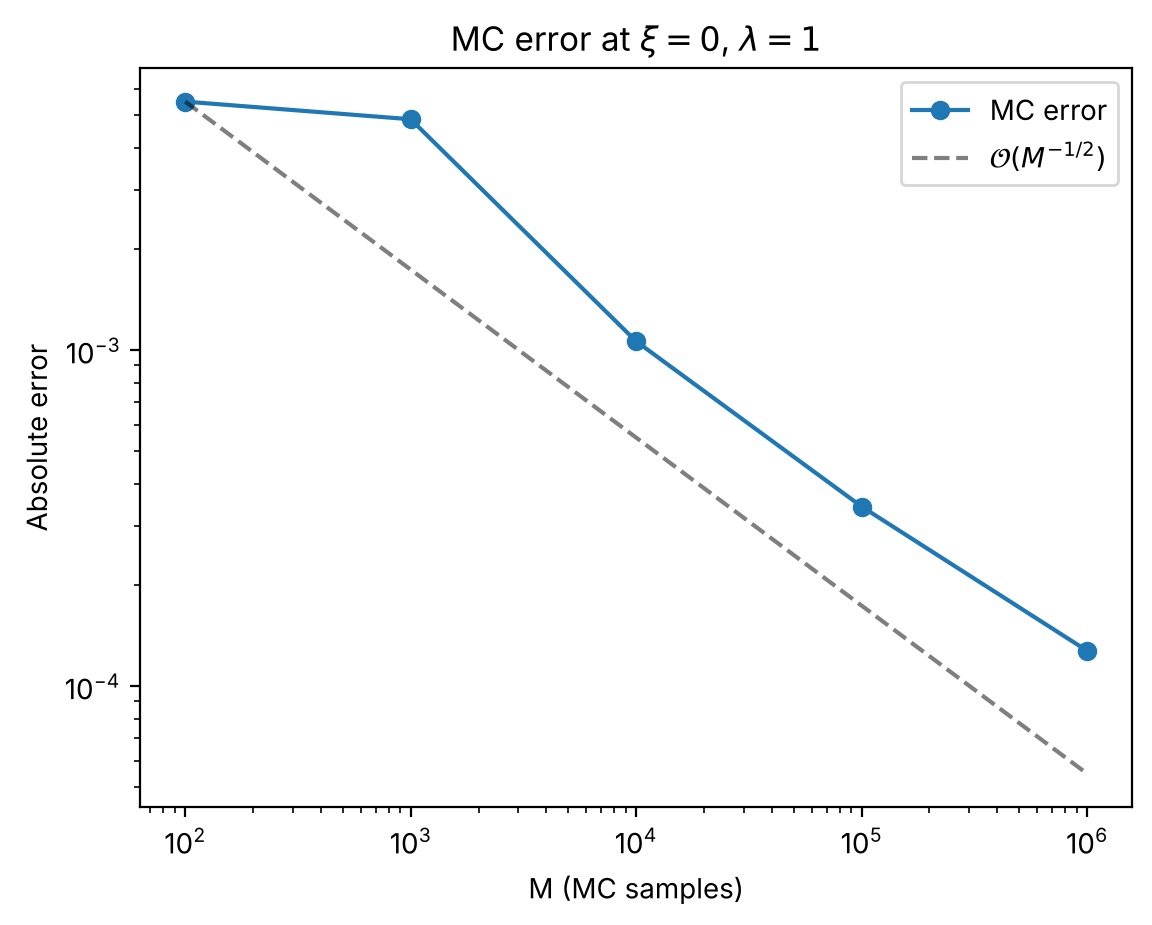

In [4]:
M_list = np.array([100, 1_000, 10_000, 100_000, 1_000_000])
n_rep = 10

mc_err, mc_time = [], []
for M in M_list:
    errs, t0 = [], time.perf_counter()
    for _ in range(n_rep):
        errs.append(abs(hjb_MC(xi, t, T, lam, M, psi=g_np)[0] - u_ref))
    mc_time.append((time.perf_counter() - t0) / n_rep)
    mc_err.append(np.mean(errs))
    print(f"M = {M:8d} | mean abs error {mc_err[-1]:.2e} | time per run {mc_time[-1]:.4f} s")
mc_err, mc_time = np.array(mc_err), np.array(mc_time)

plt.loglog(M_list, mc_err, "o-", label="MC error")
plt.loglog(M_list, mc_err[0] * (M_list / M_list[0])**-0.5, "k--", alpha=0.5, label=r"$\mathcal{O}(M^{-1/2})$")
plt.xlabel("M (MC samples)"); plt.ylabel("Absolute error")
plt.title(r"MC error at $\xi = 0$, $\lambda = 1$")
plt.legend()
plt.show()

## Deep BSDE formulation

Comparing with the general semilinear form $\partial_t u + \tfrac{1}{2}\operatorname{Tr}(\sigma\sigma^\top \nabla^2 u) + \mu\cdot\nabla u + f(t, x, u, \sigma^\top\nabla u) = 0$ gives $\mu = 0$, $\sigma = \sqrt{2}\,I$ and $f = -\lambda|\nabla u|^2$. The forward SDE is
\begin{equation}
    dX_t = \sqrt{2}\,dW_t, \qquad X_0 = \xi
\end{equation}
and with $Z_t = \sigma^\top \nabla u(t, X_t) = \sqrt{2}\,\nabla u$ we have $|\nabla u|^2 = |Z|^2/2$, so $f(Z) = -\tfrac{\lambda}{2}|Z|^2$. The BSDE $dY_t = -f\,dt + Z_t^\top dW_t$ is integrated as
\begin{equation}
    Y_{n+1} = Y_n + \frac{\lambda}{2}|Z_n|^2 \Delta t + Z_n^\top \Delta W_n
\end{equation}

Taking expectations of $Y_N = g(X_N)$ gives a useful identity (it follows from Itô's isometry):
\begin{equation}
    Y_0 = \mathbb{E}[g(X_T)] - \frac{\lambda}{2}\,\mathbb{E}\int_0^T |Z_t|^2\,dt
\end{equation}
So $Y_0$ is the linear baseline minus a correction that is set entirely by the learned $Z$. Any error in $\mathbb{E}\int|Z|^2$ is multiplied by $\lambda/2$ in $Y_0$. This becomes important for large $\lambda$.

In [5]:
def sample_paths(xi, bs, d, N, dt):
    # Brownian increments dW: (bs, N, d) and forward paths X: (bs, N+1, d) with X_0 = xi
    dW = np.sqrt(dt) * np.random.randn(bs, N, d)
    X = np.empty((bs, N + 1, d))
    X[:, 0] = xi
    X[:, 1:] = xi + np.sqrt(2) * np.cumsum(dW, axis=1)
    return torch.tensor(X, dtype=torch.float32), torch.tensor(dW, dtype=torch.float32)


def g(x):
    return torch.log(0.5 * (1 + (x**2).sum(-1)))


def make_f(lam):
    # f(y, z) = -lam/2 |z|^2
    return lambda y, z: -0.5 * lam * (z**2).sum(-1)

The two architectures from `BS_neural_comp` are reused: the original Deep BSDE with one subnet per time step, and the shared net $Z(t, x)$ for all steps.

One change is made to both. The network output is divided by $d$, $Z_n = \mathrm{NN}(X_n)/d$, as in the reference implementation by Han et al. Here the true $Z$ is small (each component is roughly $10^{-2}$). Without the scaling, Adam's first steps move every component of $Z$ by far more than that. Because $Y$ contains $\tfrac{\lambda}{2}|Z|^2$, this creates a large drift that $Y_0$ then compensates for. In tests without the scaling, $Y_0$ drifted to negative values for $\lambda \geq 10$.

The forward pass is split into `z_path` (all $Z_n$ along the paths) and the $Y$ recursion, so that $\mathbb{E}\int|Z|^2$ can be measured after training.

In [6]:
class SubNet(nn.Module):
    # Subnet for each time increment Z_t, takes dimension and width as arguments. Typically, width = d + 10
    def __init__(self, d, width):
        super().__init__()
        self.net = nn.Sequential(nn.BatchNorm1d(d),
            nn.Linear(d, width),
            nn.BatchNorm1d(width),
            nn.ReLU(),
            nn.Linear(width, width),
            nn.BatchNorm1d(width),
            nn.ReLU(),
            nn.Linear(width, d),
        )
    def forward(self, x):
        return self.net(x)


class YZnet(nn.Module):
    def __init__(self, d, dt, N, f, y0_init=(0., 1.)):
        super().__init__()
        self.N, self.dt, self.f, self.d = N, dt, f, d
        self.y0 = nn.Parameter(torch.empty(1).uniform_(*y0_init))
        self.z0 = nn.Parameter(torch.empty(d).uniform_(-0.1, 0.1) / d)
        self.subnets = nn.ModuleList([SubNet(d, d + 10) for _ in range(N - 1)])

    def z_path(self, X):
        Z = [self.z0.expand(X.shape[0], -1)]
        for n in range(self.N - 1):
            Z.append(self.subnets[n](X[:, n + 1]) / self.d)
        return torch.stack(Z, dim=1)                       # (M, N, d)

    def forward(self, X, dW):
        Z = self.z_path(X)
        y = self.y0.expand(X.shape[0])
        for n in range(self.N):
            y = y - self.f(y, Z[:, n]) * self.dt + (Z[:, n] * dW[:, n]).sum(-1)
        return y


class ZNet(nn.Module):
    # One network Z(t, x) shared over all time steps
    def __init__(self, d, width, T, x_mean, x_std):
        super().__init__()
        self.T, self.d = T, d
        self.register_buffer("x_mean", torch.as_tensor(x_mean, dtype=torch.float32))
        self.register_buffer("x_std", torch.as_tensor(x_std, dtype=torch.float32))
        self.net = nn.Sequential(
            nn.Linear(d + 1, width), nn.ELU(),
            nn.Linear(width, width), nn.ELU(),
            nn.Linear(width, d),
        )

    def forward(self, t, x):
        x = (x - self.x_mean) / self.x_std
        t = torch.full_like(x[:, :1], 2 * t / self.T - 1)   # time scaled to [-1, 1]
        return self.net(torch.cat([x, t], dim=1)) / self.d


class YZnet_shared(nn.Module):
    def __init__(self, d, dt, N, f, x_mean, x_std, y0_init=(0., 1.)):
        super().__init__()
        self.N, self.dt, self.f = N, dt, f
        self.y0 = nn.Parameter(torch.empty(1).uniform_(*y0_init))
        self.z0 = nn.Parameter(torch.empty(d).uniform_(-0.1, 0.1) / d)
        self.znet = ZNet(d, d + 10, N * dt, x_mean, x_std)

    def z_path(self, X):
        Z = [self.z0.expand(X.shape[0], -1)]
        for n in range(self.N - 1):
            Z.append(self.znet((n + 1) * self.dt, X[:, n + 1]))
        return torch.stack(Z, dim=1)

    def forward(self, X, dW):
        Z = self.z_path(X)
        y = self.y0.expand(X.shape[0])
        for n in range(self.N):
            y = y - self.f(y, Z[:, n]) * self.dt + (Z[:, n] * dW[:, n]).sum(-1)
        return y

The loss is, as before,
\begin{equation}
    \mathcal{L}(\theta) = \frac{1}{M} \sum_{m = 1}^M |Y_N^{(m)} - g(X_N^{(m)})|^2
\end{equation}
Adam is used with separate learning rates for $Y_0$ and the $Z$ networks. The subnet model uses the rate $10^{-2}$; the shared model uses $10^{-3}$, as in `BS_neural_comp`. Both rates are divided by 10 at 60 % and again at 85 % of the iterations. The training function also records wall-clock time, which is needed for the cost comparison. Because $Y_0$ fluctuates with the batch noise, the reported estimate is the mean of the last 100 iterates.

In [7]:
def make_opt(model, lr_y0=1e-1, lr_z=1e-2):
    y0_params = [model.y0]
    z_params = [p for name, p in model.named_parameters() if name != "y0"]
    return torch.optim.Adam([
        {"params": y0_params, "lr": lr_y0},
        {"params": z_params, "lr": lr_z},
    ])


def loss_fn(model, X, dW):
    return ((model(X, dW) - g(X[:, -1]))**2).mean()


def train(model, opt, batch_size, n_iter, d, N, dt, xi, verbose: bool = True):
    sched = torch.optim.lr_scheduler.MultiStepLR(opt, milestones=[int(0.6 * n_iter), int(0.85 * n_iter)], gamma=0.1)
    y0_hist, loss_hist, time_hist = np.zeros(n_iter), np.zeros(n_iter), np.zeros(n_iter)
    t0 = time.perf_counter()
    for i in range(n_iter):
        opt.zero_grad()
        X, dW = sample_paths(xi, batch_size, d=d, N=N, dt=dt)
        loss = loss_fn(model, X, dW)
        loss.backward()
        opt.step()
        sched.step()

        loss_hist[i] = loss.item()
        y0_hist[i] = model.y0.item()
        time_hist[i] = time.perf_counter() - t0
        if verbose and i % 250 == 0:
            print(f"iter {i:5d} | loss {loss_hist[i]:.4f} | Y0 {y0_hist[i]:.4f}")
    return loss_hist, y0_hist, time_hist


def make_models(lam, N, dt, seed=0):
    # Fresh models + optimizers (pilot statistics for the shared net's input standardization)
    f = make_f(lam)
    X_p, _ = sample_paths(xi, 2_000, d=d, N=N, dt=dt)
    x_mean, x_std = X_p.mean(dim=(0, 1)), X_p.std(dim=(0, 1)) + 1e-8
    torch.manual_seed(seed)
    m_orig = YZnet(d=d, dt=dt, N=N, f=f)
    torch.manual_seed(seed)
    m_shared = YZnet_shared(d=d, dt=dt, N=N, f=f, x_mean=x_mean, x_std=x_std)
    return {"Original": (m_orig, make_opt(m_orig, lr_z=1e-2)),
            "Shared":   (m_shared, make_opt(m_shared, lr_z=1e-3))}

## Training at $\lambda = 1$

Both models are trained for 1000 iterations with batch size 64.

In [ ]:
N = 20
dt = T / N
n_iter = 1000
batch_size = 64

runs = {}
for name, (model, opt) in make_models(lam, N, dt).items():
    print(f"--- {name}")
    np.random.seed(1)                       # same path stream for both models
    runs[name] = (model, *train(model, opt, batch_size, n_iter, d, N, dt, xi))
    y0_est = runs[name][2][-100:].mean()
    print(f"{name}: Y0 = {y0_est:.4f} | ref {u_ref:.4f} | rel. error {abs(y0_est - u_ref)/u_ref:.2e} | {runs[name][3][-1]:.1f} s\n")

--- Original
iter     0 | loss 16.8380 | Y0 0.5963


iter   250 | loss 0.0257 | Y0 4.5806


iter   500 | loss 0.0233 | Y0 4.6038


iter   750 | loss 0.0193 | Y0 4.6078


iter  1000 | loss 0.0131 | Y0 4.6036


iter  1250 | loss 0.0240 | Y0 4.5983


... (7 outputs left out)

iter  1250 | loss 0.0181 | Y0 4.6002


iter  1500 | loss 0.0137 | Y0 4.5985


iter  1750 | loss 0.0183 | Y0 4.6029


Shared: Y0 = 4.6004 | ref 4.5901 | rel. error 2.23e-03 | 34.7 s



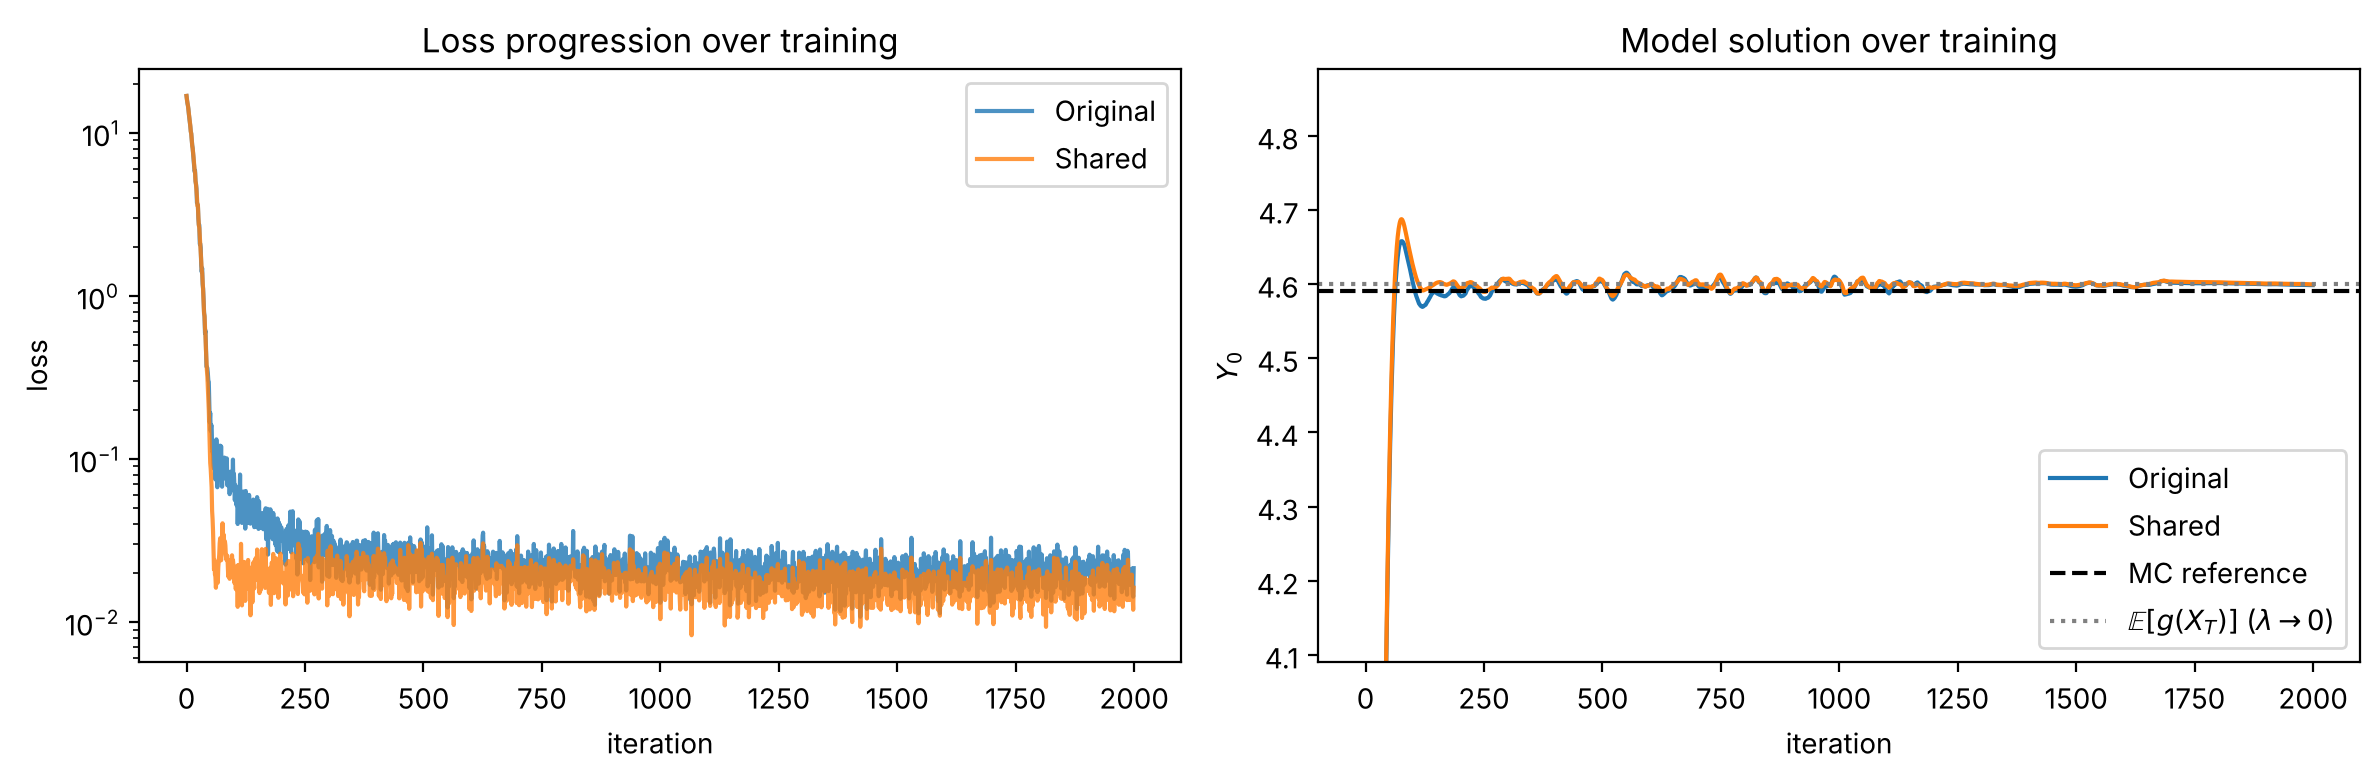

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, (model, loss_h, y0_h, time_h) in runs.items():
    axes[0].semilogy(loss_h, label=name, alpha=0.8)
    axes[1].plot(y0_h, label=name)
axes[1].axhline(u_ref, color="k", ls="--", label="MC reference")
axes[1].axhline(g_mean, color="gray", ls=":", label=r"$\mathbb{E}[g(X_T)]$ ($\lambda \to 0$)")
axes[1].set_ylim(u_ref - 0.5, u_ref + 0.3)
axes[0].set(xlabel="iteration", ylabel="loss", title="Loss progression over training")
axes[1].set(xlabel="iteration", ylabel="$Y_0$", title="Model solution over training")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

## Cost vs accuracy

The Deep BSDE error is shown as a function of training time, using the running mean of the last 100 iterates of $Y_0$. The MC error is shown as a function of the time per run from the convergence study above. The dotted line is the error of the linear baseline $\mathbb{E}[g(X_T)]$.

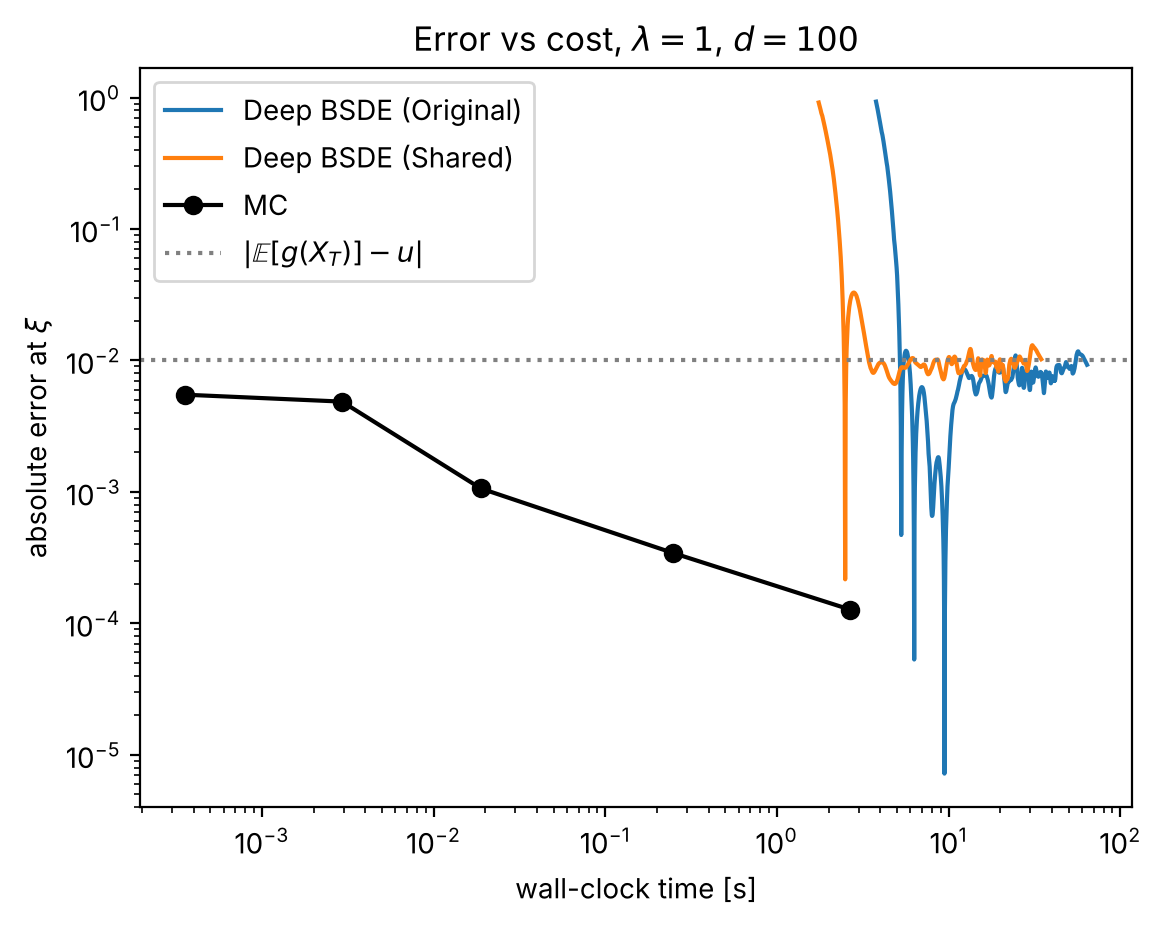

In [10]:
def running_mean(x, w=100):
    c = np.cumsum(np.insert(x, 0, 0.0))
    return (c[w:] - c[:-w]) / w

for name, (model, loss_h, y0_h, time_h) in runs.items():
    plt.loglog(time_h[99:], np.abs(running_mean(y0_h) - u_ref), label=f"Deep BSDE ({name})")
plt.loglog(mc_time, mc_err, "o-", color="k", label="MC")
plt.axhline(abs(g_mean - u_ref), color="gray", ls=":", label=r"$|\mathbb{E}[g(X_T)] - u|$")
plt.xlabel("wall-clock time [s]"); plt.ylabel("absolute error at $\\xi$")
plt.title(r"Error vs cost, $\lambda = 1$, $d = 100$")
plt.legend()
plt.show()

# Everything below this cell is essentialy an unprompted Claude output

Claude spent about an hour setting up and running the experiments below by own judgement. Their relevance to the project or level of accuracy/truthfullness has not been verified by the author. Viewer discretion is advised.

## Large $\lambda$

Both methods degrade as $\lambda$ grows, but for different reasons.

- **MC.** The weights $e^{-\lambda g}$ become increasingly skewed: the estimate is dominated by the few samples with the smallest $g(X_T)$. The relative variance of $\bar w$ grows roughly like $e^{\lambda^2 \mathrm{Var}(g)} - 1$, so more samples are needed and the ESS shrinks.
- **Deep BSDE.** By the identity above, $Y_0 = \mathbb{E}[g] - \tfrac{\lambda}{2}\mathbb{E}\int |Z|^2 dt$. The network must learn $Z$ well enough that the variance it explains is correct to within $2\varepsilon/\lambda$ for an error $\varepsilon$ in $Y_0$.

For each $\lambda$: a reference with $M = 4\cdot 10^6$, MC with a fixed budget $M = 10^5$ (5 repetitions), and both Deep BSDE models trained as above. After training, $\tfrac{\lambda}{2}\mathbb{E}\int|Z|^2dt$ is estimated on fresh paths and compared with the value the exact solution requires, $\mathbb{E}[g(X_T)] - u_{\text{ref}}$.

In [11]:
@torch.no_grad()
def z_correction(model, lam, n_paths=4_096):
    # lam/2 * E int |Z|^2 dt, estimated on fresh paths
    model.eval()
    X, _ = sample_paths(xi, n_paths, d=d, N=N, dt=dt)
    Z = model.z_path(X)
    model.train()
    return (0.5 * lam * (Z**2).sum(-1).sum(-1) * dt).mean().item()


lams = [1, 5, 10, 25, 50]
M_mc = 100_000
sweep = {k: [] for k in ["ref", "ref_se", "mc_err", "mc_se", "ess", "Original", "Shared",
                         "corr_needed", "corr_Original", "corr_Shared"]}

for lam_ in lams:
    u_r, se_r, _ = hjb_MC(xi, t, T, lam_, 4_000_000, psi=g_np)
    mc_runs = [hjb_MC(xi, t, T, lam_, M_mc, psi=g_np) for _ in range(5)]
    sweep["ref"].append(u_r); sweep["ref_se"].append(se_r)
    sweep["mc_err"].append(np.mean([abs(r[0] - u_r) for r in mc_runs]))
    sweep["mc_se"].append(np.mean([r[1] for r in mc_runs]))
    sweep["ess"].append(np.mean([r[2] for r in mc_runs]))
    sweep["corr_needed"].append(g_mean - u_r)

    for name, (model, opt) in make_models(lam_, N, dt).items():
        np.random.seed(1)
        _, y0_h, time_h = train(model, opt, batch_size, n_iter, d, N, dt, xi, verbose=False)
        sweep[name].append(y0_h[-100:].mean())
        sweep["corr_" + name].append(z_correction(model, lam_))

    print(f"lam = {lam_:3d} | ref {u_r:.4f} +- {se_r:.1e} | MC(1e5) err {sweep['mc_err'][-1]:.1e}, ESS {sweep['ess'][-1]:.0f} "
          f"| Original {sweep['Original'][-1]:.4f} | Shared {sweep['Shared'][-1]:.4f}")
sweep = {k: np.array(v) for k, v in sweep.items()}

lam =   1 | ref 4.5901 +- 7.2e-05 | MC(1e5) err 4.6e-04, ESS 97974 | Original 4.5994 | Shared 4.6003


lam =   5 | ref 4.5485 +- 8.6e-05 | MC(1e5) err 5.7e-04, ESS 56846 | Original 4.5963 | Shared 4.5978


lam =  10 | ref 4.4931 +- 1.6e-04 | MC(1e5) err 1.2e-03, ESS 6503 | Original 4.5901 | Shared 4.5943


lam =  25 | ref 4.3030 +- 6.4e-03 | MC(1e5) err 3.3e-02, ESS 12 | Original 3.8878 | Shared 4.5829


lam =  50 | ref 4.0724 +- 1.5e-02 | MC(1e5) err 6.0e-02, ESS 2 | Original 3.0729 | Shared 4.5613


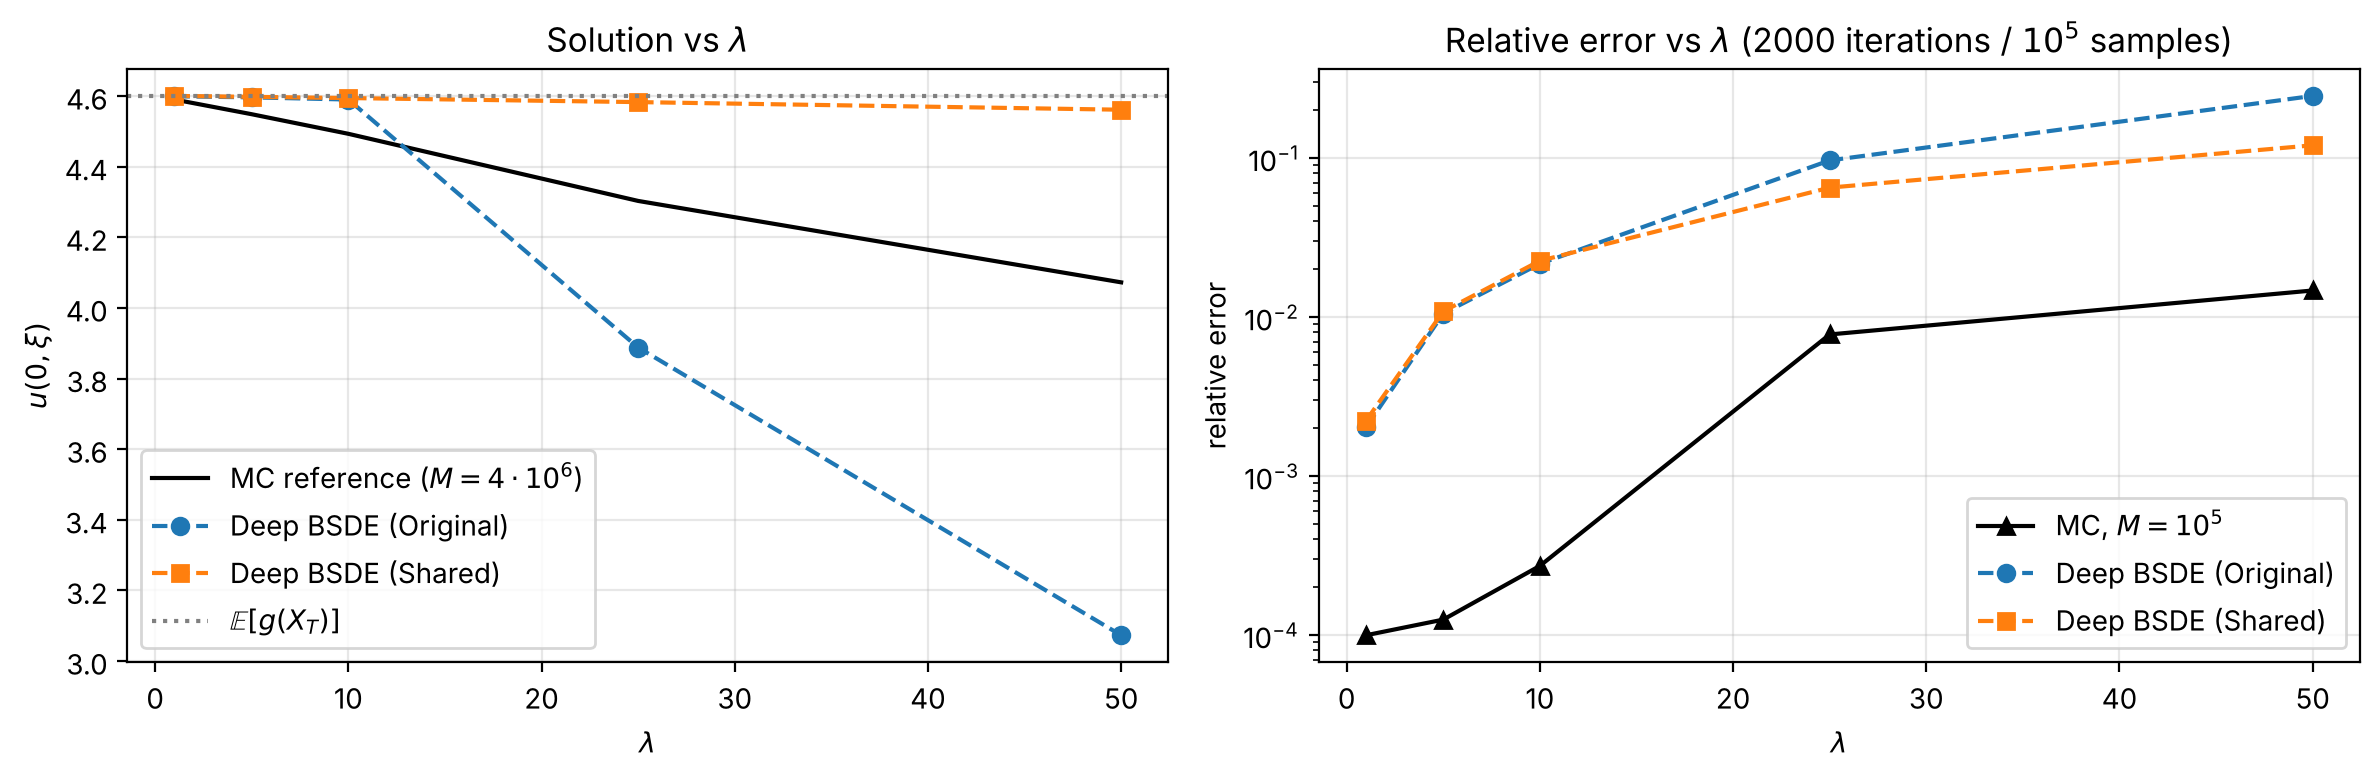

 lam | MC ESS (of 1e5) |  needed lam/2 E int|Z|^2 |  Original |    Shared
   1 |           97974 |                   0.0100 |    0.0008 |    0.0006
   5 |           56846 |                   0.0517 |    0.0037 |    0.0032
  10 |            6503 |                   0.1071 |    0.0098 |    0.0067
  25 |              12 |                   0.2972 |    0.7069 |    0.0182
  50 |               2 |                   0.5278 |    1.5149 |    0.0398


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(lams, sweep["ref"], "k-", label="MC reference ($M = 4\\cdot10^6$)")
axes[0].plot(lams, sweep["Original"], "o--", label="Deep BSDE (Original)")
axes[0].plot(lams, sweep["Shared"], "s--", label="Deep BSDE (Shared)")
axes[0].axhline(g_mean, color="gray", ls=":", label=r"$\mathbb{E}[g(X_T)]$")
axes[0].set(xlabel=r"$\lambda$", ylabel=r"$u(0, \xi)$", title=r"Solution vs $\lambda$")

axes[1].semilogy(lams, sweep["mc_err"] / sweep["ref"], "k^-", label="MC, $M = 10^5$")
axes[1].semilogy(lams, np.abs(sweep["Original"] - sweep["ref"]) / sweep["ref"], "o--", label="Deep BSDE (Original)")
axes[1].semilogy(lams, np.abs(sweep["Shared"] - sweep["ref"]) / sweep["ref"], "s--", label="Deep BSDE (Shared)")
axes[1].set(xlabel=r"$\lambda$", ylabel="relative error", title="Relative error vs $\\lambda$ (2000 iterations / $10^5$ samples)")
for ax in axes:
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"{'lam':>4} | {'MC ESS (of 1e5)':>15} | {'needed lam/2 E int|Z|^2':>24} | {'Original':>9} | {'Shared':>9}")
for i, lam_ in enumerate(lams):
    print(f"{lam_:4d} | {sweep['ess'][i]:15.0f} | {sweep['corr_needed'][i]:24.4f} | "
          f"{sweep['corr_Original'][i]:9.4f} | {sweep['corr_Shared'][i]:9.4f}")

The table compares the correction $\tfrac{\lambda}{2}\mathbb{E}\int|Z|^2dt$ required by the reference solution with the one produced by the learned $Z$. If the identity is the explanation, the gap between these two columns should roughly match the $Y_0$ error in the plot. Note that $Y_0$ and $Z$ are trained jointly, so the match is approximate (the loss only enforces it on average over training batches).

### Larger training budget at $\lambda = 10$

To check whether the Deep BSDE error is a budget problem or a defect in the setup, the shared model is retrained at $\lambda = 10$ with batch size 512 and 4000 iterations, i.e. 16 times as many sampled paths. The gradient signal that determines $Z$ is weak compared with the batch noise ($\mathrm{Var}(g(X_T)) \approx 0.02$ is small), so a larger batch should help if the problem is noise. This cell takes about 5 minutes.

Reference                      : 4.4931
Shared, batch 64,  2000 iters  : 4.5943 (rel. error 2.25e-02)
Shared, batch 512, 4000 iters  : 4.5340 (rel. error 9.12e-03, 334 s)


lam/2 E int|Z|^2 needed / learned: 0.1071 / 0.0665


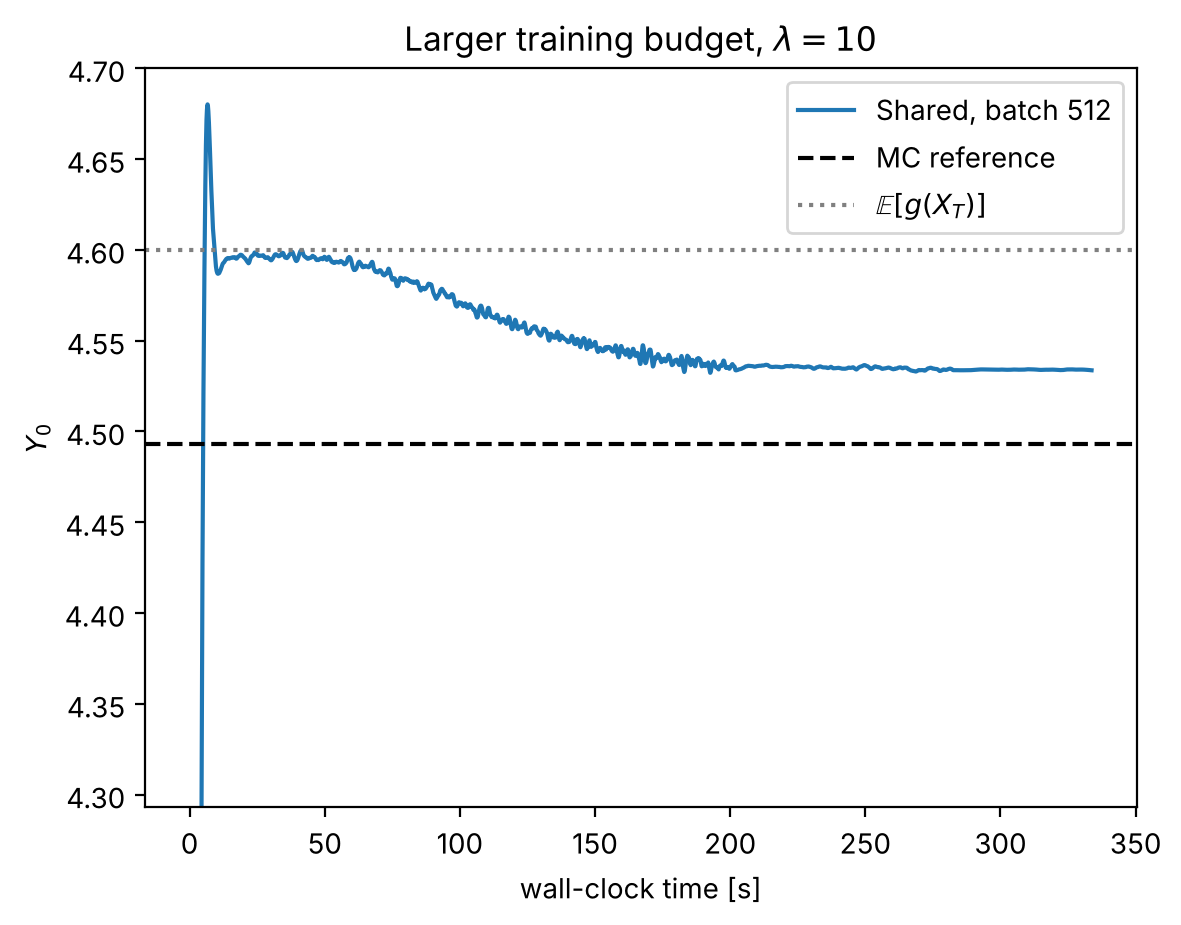

In [13]:
lam = 10.0
i10 = lams.index(10)
model, opt = make_models(lam, N, dt)["Shared"]
np.random.seed(1)
_, y0_big, time_big = train(model, opt, batch_size=512, n_iter=4000, d=d, N=N, dt=dt, xi=xi, verbose=False)
y0_big_est = y0_big[-100:].mean()

print(f"Reference                      : {sweep['ref'][i10]:.4f}")
print(f"Shared, batch 64,  2000 iters  : {sweep['Shared'][i10]:.4f} (rel. error {abs(sweep['Shared'][i10] - sweep['ref'][i10]) / sweep['ref'][i10]:.2e})")
print(f"Shared, batch 512, 4000 iters  : {y0_big_est:.4f} (rel. error {abs(y0_big_est - sweep['ref'][i10]) / sweep['ref'][i10]:.2e}, {time_big[-1]:.0f} s)")
print(f"lam/2 E int|Z|^2 needed / learned: {sweep['corr_needed'][i10]:.4f} / {z_correction(model, lam):.4f}")

plt.plot(time_big, y0_big, label="Shared, batch 512")
plt.axhline(sweep["ref"][i10], color="k", ls="--", label="MC reference")
plt.axhline(g_mean, color="gray", ls=":", label=r"$\mathbb{E}[g(X_T)]$")
plt.ylim(sweep["ref"][i10] - 0.2, g_mean + 0.1)
plt.xlabel("wall-clock time [s]"); plt.ylabel("$Y_0$")
plt.title(r"Larger training budget, $\lambda = 10$")
plt.legend()
plt.show()

## Many evaluation points

MC and the single-point Deep BSDE both return one value, $u(0, \xi)$, per run. To get $u(0, \cdot)$ on a region, the Deep BSDE is changed (the extension in the project proposal): $X_0$ is sampled from the region and $Y_0 = \mathrm{NN}_y(X_0)$ replaces the scalar parameter. Since $X_0$ now varies, $Z_0$ also has to be a function of $X_0$, so the shared net is used for every step including $n = 0$.

Uniform sampling of a box $[-a, a]^d$ is a poor choice in $d = 100$: $|X_0|^2$ concentrates near $d a^2/3$, so $u(0, \cdot)$ hardly varies over the samples. In a test run, the network error was larger than that variation. Instead the region is the diagonal segment $X_0 = s\,(1, \dots, 1)$, $s \in [-1, 1]$, where $|X_0|^2 = d s^2$ ranges from 0 to 100 and $u(0, \cdot)$ varies by about $0.4$.

The trained network is compared with MC at 21 points on the segment. The break-even number of points is then estimated as the training time divided by the MC time per point at the same accuracy.

In [14]:
lam = 1.0
f = make_f(lam)
a = 1.0

def sample_paths_line(bs, d, N, dt, a):
    s = np.random.uniform(-a, a, (bs, 1))
    x0 = s * np.ones(d)
    dW = np.sqrt(dt) * np.random.randn(bs, N, d)
    X = np.empty((bs, N + 1, d))
    X[:, 0] = x0
    X[:, 1:] = x0[:, None] + np.sqrt(2) * np.cumsum(dW, axis=1)
    return torch.tensor(X, dtype=torch.float32), torch.tensor(dW, dtype=torch.float32)


class YZnet_region(nn.Module):
    def __init__(self, d, dt, N, f, x_mean, x_std):
        super().__init__()
        self.N, self.dt, self.f = N, dt, f
        self.register_buffer("x_mean", torch.as_tensor(x_mean, dtype=torch.float32))
        self.register_buffer("x_std", torch.as_tensor(x_std, dtype=torch.float32))
        self.ynet = nn.Sequential(nn.Linear(d, d + 10), nn.ELU(),
                                  nn.Linear(d + 10, d + 10), nn.ELU(),
                                  nn.Linear(d + 10, 1))
        self.znet = ZNet(d, d + 10, N * dt, x_mean, x_std)

    def u0(self, x):
        return self.ynet((x - self.x_mean) / self.x_std).squeeze(-1)

    def forward(self, X, dW):
        y = self.u0(X[:, 0])
        for n in range(self.N):
            z = self.znet(n * self.dt, X[:, n])
            y = y - self.f(y, z) * self.dt + (z * dW[:, n]).sum(-1)
        return y


torch.manual_seed(0); np.random.seed(0)
X_p, _ = sample_paths_line(2_000, d, N, dt, a)
region_model = YZnet_region(d, dt, N, f, X_p.mean(dim=(0, 1)), X_p.std(dim=(0, 1)) + 1e-8)
region_opt = torch.optim.Adam(region_model.parameters(), lr=1e-3)

n_iter_region = 3000
sched = torch.optim.lr_scheduler.MultiStepLR(region_opt, [int(0.6 * n_iter_region), int(0.85 * n_iter_region)], 0.1)
region_loss = np.zeros(n_iter_region)
t0 = time.perf_counter()
for i in range(n_iter_region):
    region_opt.zero_grad()
    X, dW = sample_paths_line(128, d, N, dt, a)
    loss = loss_fn(region_model, X, dW)
    loss.backward()
    region_opt.step()
    sched.step()
    region_loss[i] = loss.item()
    if i % 500 == 0:
        print(f"iter {i:5d} | loss {region_loss[i]:.4f}")
t_train_region = time.perf_counter() - t0
print(f"Training time: {t_train_region:.1f} s")

iter     0 | loss 22.9512


iter   500 | loss 0.0235


iter  1000 | loss 0.0152


iter  1500 | loss 0.0147


iter  2000 | loss 0.0103


iter  2500 | loss 0.0134


Training time: 74.5 s


Deep BSDE on segment: mean abs error 0.0102, max 0.0453


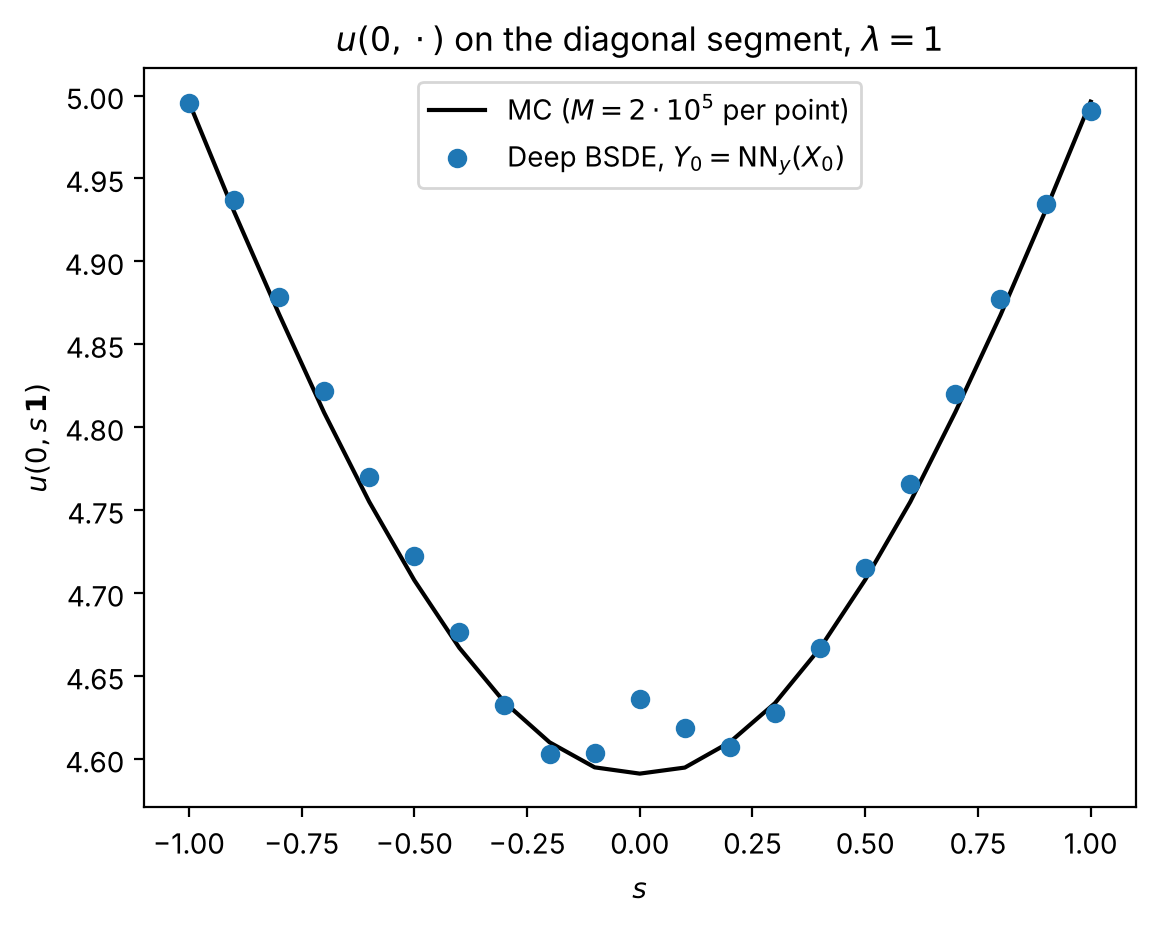

In [15]:
s_test = np.linspace(-a, a, 21)
x_test = s_test[:, None] * np.ones(d)

mc_test = np.array([hjb_MC(x, t, T, lam, 200_000, psi=g_np) for x in x_test])
with torch.no_grad():
    nn_test = region_model.u0(torch.tensor(x_test, dtype=torch.float32)).numpy()

err_region = np.abs(nn_test - mc_test[:, 0])
print(f"Deep BSDE on segment: mean abs error {err_region.mean():.4f}, max {err_region.max():.4f}")

plt.plot(s_test, mc_test[:, 0], "k-", label="MC ($M = 2\\cdot 10^5$ per point)")
plt.plot(s_test, nn_test, "o", label="Deep BSDE, $Y_0 = \\mathrm{NN}_y(X_0)$")
plt.xlabel("$s$"); plt.ylabel(r"$u(0, s\,\mathbf{1})$")
plt.title(r"$u(0, \cdot)$ on the diagonal segment, $\lambda = 1$")
plt.legend()
plt.show()

For the break-even point, the MC sample count needed to match the network's mean error is $M^* = (\sigma_1/\varepsilon)^2$, where $\sigma_1 = \mathrm{SE}\cdot\sqrt{M}$ is the per-sample standard deviation of the MC estimator. Then $M^*$ is timed directly. A floor of $M = 1000$ is used so that the delta-method SE remains meaningful.

In [16]:
sigma_1 = np.mean(mc_test[:, 1]) * np.sqrt(200_000)
M_star = max(int(np.ceil((sigma_1 / err_region.mean())**2)), 1_000)

t0 = time.perf_counter()
for x in x_test:
    hjb_MC(x, t, T, lam, M_star, psi=g_np)
t_mc_point = (time.perf_counter() - t0) / len(x_test)

print(f"Per-sample std of MC estimator : {sigma_1:.3f}")
print(f"MC samples to match NN accuracy: M* = {M_star}")
print(f"MC time per point at M*        : {t_mc_point*1e3:.2f} ms")
print(f"Deep BSDE training time        : {t_train_region:.1f} s")
print(f"Break-even number of points    : {t_train_region / t_mc_point:,.0f}")

Per-sample std of MC estimator : 0.141
MC samples to match NN accuracy: M* = 1000
MC time per point at M*        : 2.31 ms
Deep BSDE training time        : 74.5 s
Break-even number of points    : 32,228


## Discussion / comment

The numbers below refer to the run stored in this notebook. Timings are from a 2-core CPU.

**MC via Cole–Hopf.** The MC solver reproduces the paper's value ($4.59014$ vs. $4.5901$) and converges as $\mathcal{O}(M^{-1/2})$. An error of about $10^{-3}$ takes roughly 0.02 s. With a closed-form expectation and no time stepping, MC is a very strong baseline here.

**Deep BSDE at $\lambda = 1$.** Both models reach a relative error of about 0.2 %, close to the paper's reported 0.17 %. However, this is the same as the error of the linear baseline $\mathbb{E}[g(X_T)]$ (about 0.22 %). The $Z$ diagnostic confirms what happened: the learned correction $\tfrac{\lambda}{2}\mathbb{E}\int|Z|^2dt$ is about $10^{-3}$, whereas the reference requires $10^{-2}$. With 2000 iterations of batch size 64, the networks have essentially not learned $Z$. Because the nonlinear effect is only 0.2 % of $u$ at $\lambda = 1$, this test case cannot tell a working $Z$ from a near-zero one. In error vs. time, MC is about two orders of magnitude more accurate at equal cost, and the Deep BSDE error flattens out at the baseline error.

**Large $\lambda$.** The Deep BSDE error grows with $\lambda$ as the identity $Y_0 = \mathbb{E}[g] - \tfrac{\lambda}{2}\mathbb{E}\int|Z|^2dt$ predicts. The shared model stays near $\mathbb{E}[g]$ (2.2 % error at $\lambda = 10$, 12 % at $\lambda = 50$). The original subnet model becomes unstable for $\lambda \geq 25$ and overshoots the correction by a factor of 2–3. With 16 times more sampled paths (batch 512, 4000 iterations, about 5.5 min), the error at $\lambda = 10$ falls from 2.2 % to 0.9 %, and about 60 % of the required correction is learned. The method is therefore limited by budget and gradient noise rather than broken. Progress also stops at the first learning-rate drop, so a later schedule would probably help. MC also degrades: the ESS out of $10^5$ samples falls from about 98 000 ($\lambda = 1$) to 6 500 ($\lambda = 10$), 12 ($\lambda = 25$) and 2 ($\lambda = 50$). At $\lambda \geq 25$ even the $4\cdot 10^6$-sample reference rests on a few samples, so it is only reliable to roughly 1 %, and its delta-method SE should not be trusted. For large $\lambda$, neither method is reliable without extra work (for example importance sampling or a larger $M$ for MC, and much more training for Deep BSDE).

**Many evaluation points.** With $Y_0 = \mathrm{NN}_y(X_0)$, the Deep BSDE gives $u(0, \cdot)$ on the whole segment after 75 s of training. The mean error is 0.010 and the maximum is 0.045, with the largest errors near $s = 0$. MC needs only about $10^3$ samples (about 2 ms) per point to match that accuracy. Training pays off only after about $3\cdot 10^4$ evaluation points.

**When is Deep BSDE preferable?** For this HJB problem MC wins on cost, on accuracy, and on reliability of the error estimate, unless $u$ is needed at tens of thousands of points. The case for Deep BSDE is problems where no Feynman–Kac or Cole–Hopf representation exists, such as Allen–Cahn, where MC does not apply. It also applies when a cheap surrogate for $u(0, \cdot)$ (and $\nabla u$) over a region is needed many times. A further lesson for the project: compare Deep BSDE results with the linear baseline $\mathbb{E}[g(X_T)]$, not only with the reference value. Otherwise a model that has not learned $Z$ can still appear accurate.

Caveat: the Deep BSDE hyperparameters (learning rates, $Z/d$ scaling, schedule, batch size) were set from the paper and from `BS_neural_comp`, with little tuning. The conclusions about Deep BSDE accuracy are therefore conclusions about this budget.